# Cvičenie 3

Adaptívna ekvalizácia histogramu

Knižnice: NumPy + Matplotlib + Scikit-image

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import skimage as sk

Funkcia na zobrazenie obrázku a histogramu:

In [2]:
matplotlib.rcParams['font.size'] = 10
def plot_img_and_hist(image, axes, bins=256*2):
    """Plot an image along with its histogram and cumulative histogram."""
    image = sk.util.img_as_float(image)
    ax_img, ax_hist = axes
    ax_cdf = ax_hist.twinx()

    # Display image
    ax_img.imshow(image, cmap=plt.cm.gray, vmin=0, vmax=1)
    ax_img.set_axis_off()

    # Display histogram
    ax_hist.hist(image.ravel(), bins=bins, histtype='step', color='black')
    ax_hist.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
    ax_hist.set_xlabel('Pixel intensity')
    ax_hist.set_xlim(0, 1)
    ax_hist.set_yticks([])

    # Display cumulative distribution
    img_cdf, bins = sk.exposure.cumulative_distribution(image, bins)
    ax_cdf.plot(bins, img_cdf, 'r')
    ax_cdf.set_ylim(0, 1)
    ax_cdf.set_yticks([])

    return ax_img, ax_hist, ax_cdf

## Úloha 1

Obrázok zrotujte o 32 stupňov.
Porovnajte vplyv rádu interpolácie (najbližší sused, bilineárna, bikubická) na sk.transform.rotate.

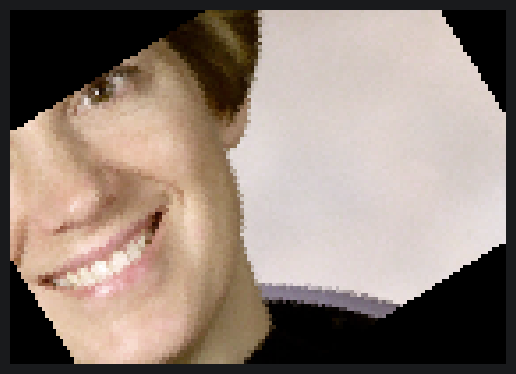

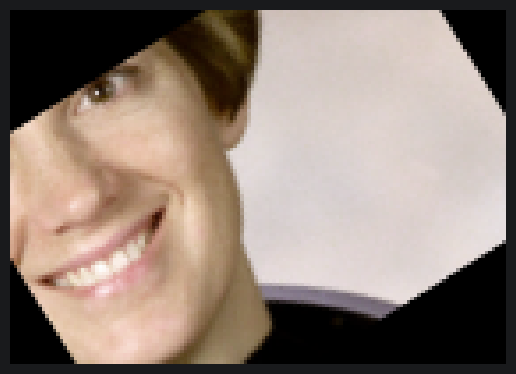

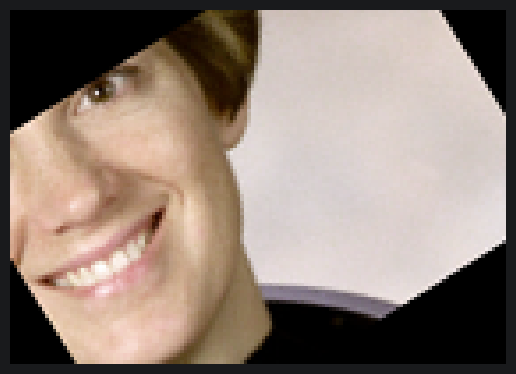

In [3]:
img2 = sk.data.astronaut()[100:200,200:340,:]
img2_rot0 = sk.transform.rotate(img2, 32, order=0)
img2_rot1 = sk.transform.rotate(img2, 32, order=1)
img2_rot2 = sk.transform.rotate(img2, 32, order=3)
plt.imshow(img2_rot0); plt.axis('off'); plt.show()
plt.imshow(img2_rot1); plt.axis('off'); plt.show()
plt.imshow(img2_rot2); plt.axis('off'); plt.show()

## Úloha 2

Globálna ekvalizácia histogramu.

Doplňte nasledujúci kód podľa komentárov.

Výsledok porovnajte s sk.exposure.equalize_hist.

In [4]:
img = sk.data.camera() # image load
img = np.clip(img, 20, None)

imhist, _ = np.histogram(img.ravel(), bins=256, range=(0, 256)) # histogram - pocet pixelov na danej urovni
cdf = imhist.cumsum() # kumulativna distribucna funkcia (CDF) - kumulativna suma cez histogram
cdf_min = cdf[cdf > 0].min() # najdenie najnizsej cdf hodnoty väčšej ako 0
print(cdf_min) 
cdf_max = cdf[-1] # pocet pixelov - posledny prvok vektora cdf
scaled = (cdf - cdf_min) / (cdf_max - cdf_min) * 255
# look up table
lut = np.clip(np.round(scaled), 0, 255).astype(np.uint8)

img_eq = lut[img]
img_eq2 = sk.exposure.equalize_hist(img)

21239


Vykreslenie:

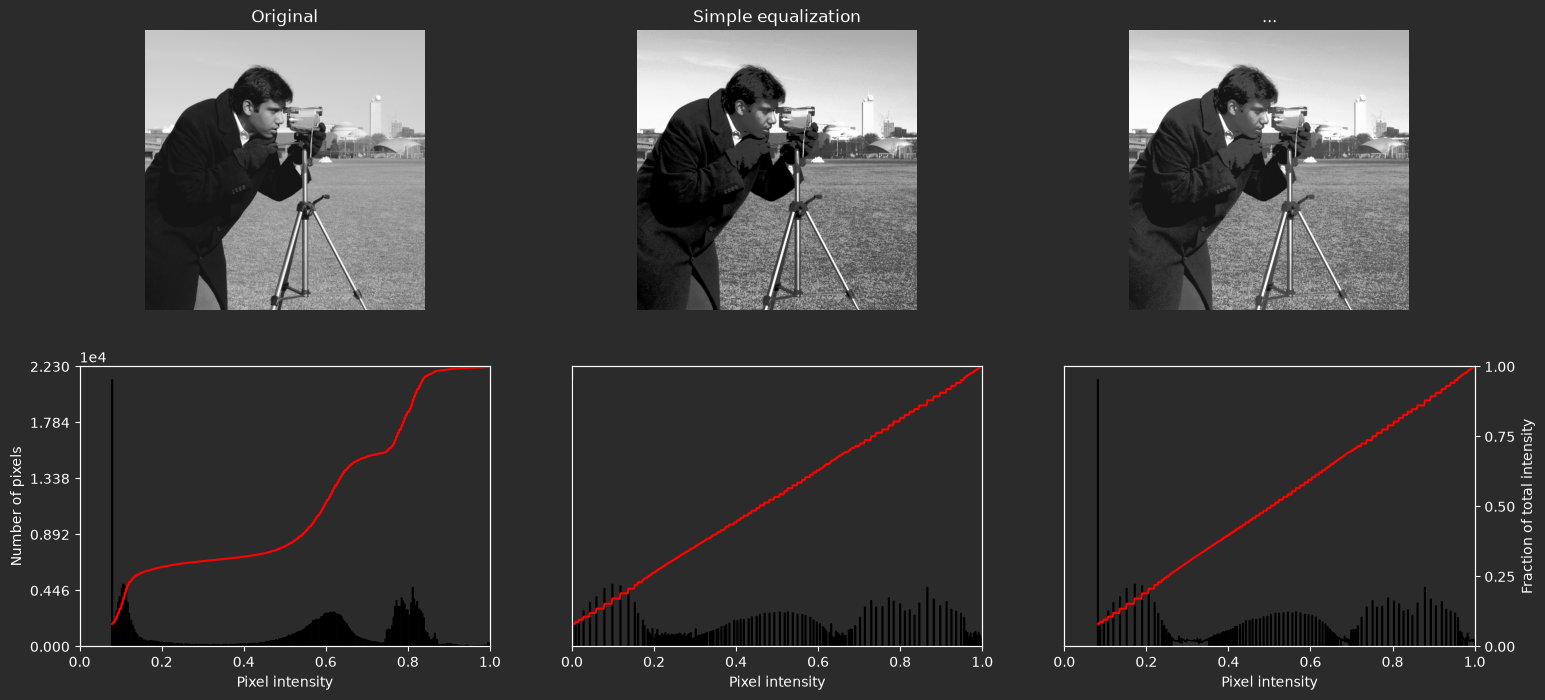

In [6]:
fig = plt.figure(figsize=(18, 8))
axes = np.zeros((2, 3), dtype=object)
axes[0, 0] = fig.add_subplot(2, 3, 1)
for i in range(1, 3):
    axes[0, i] = fig.add_subplot(2, 3, 1 + i, sharex=axes[0, 0], sharey=axes[0, 0])
for i in range(0, 3):
    axes[1, i] = fig.add_subplot(2, 3, 4 + i)

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img, axes[:, 0])
ax_img.set_title('Original')

y_min, y_max = ax_hist.get_ylim()
ax_hist.set_ylabel('Number of pixels')
ax_hist.set_yticks(np.linspace(0, y_max, 6))

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_eq, axes[:, 1])
ax_img.set_title('Simple equalization')

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_eq2, axes[:, 2])
ax_img.set_title('...')

ax_cdf.set_ylabel('Fraction of total intensity')
ax_cdf.set_yticks(np.linspace(0, 1, 5));

## Úloha 3
Porovnajte globálnu ekvalizáciu s funkciou **equalize_adapthist**.

Zistite vplyv parametra **clip_limit** na výsledný obrázok.

In [51]:
img=sk.data.moon()
img_eq = sk.exposure.equalize_hist(img)
img_eqadapt = sk.exposure.equalize_adapthist(img, clip_limit = 0.03)
img_eqadapt2 = sk.exposure.equalize_adapthist(img, clip_limit = 0.1)

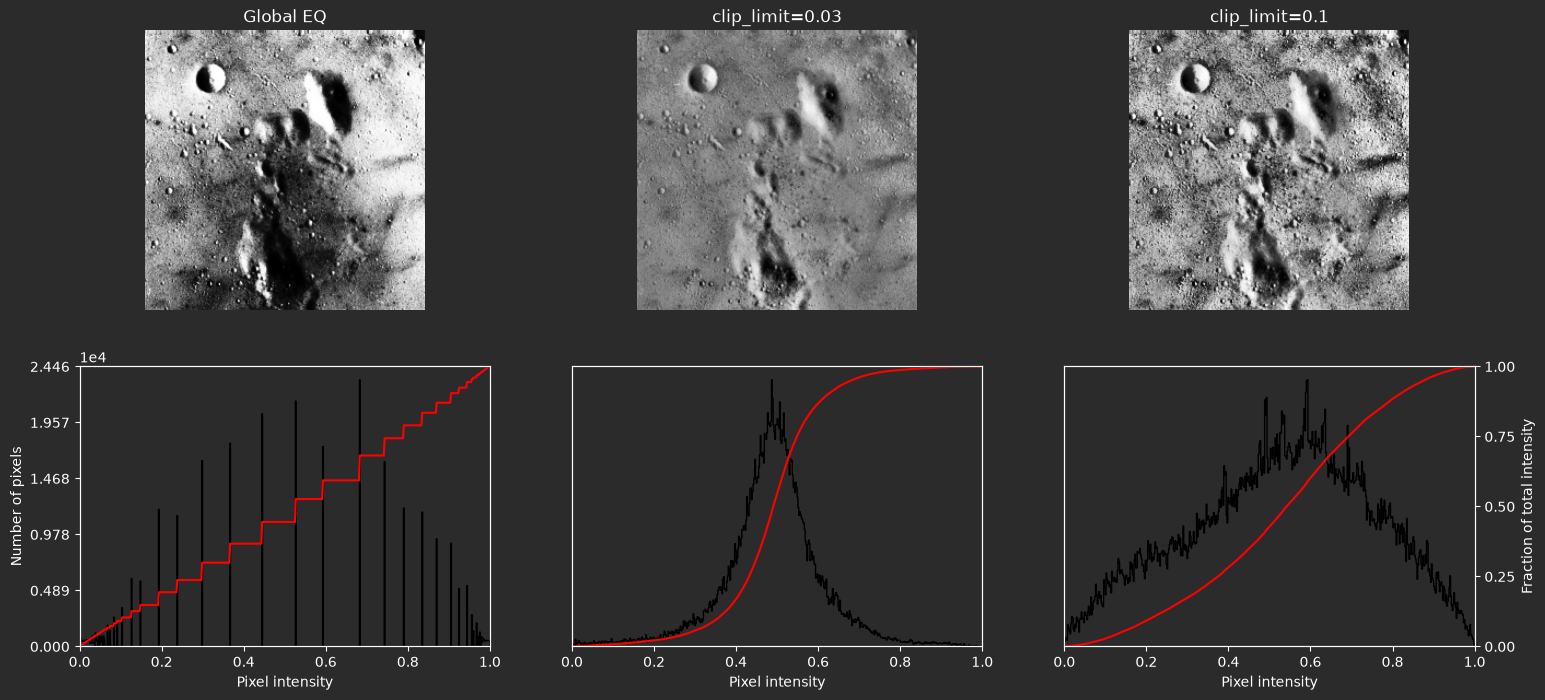

In [52]:
fig = plt.figure(figsize=(18, 8))
axes = np.zeros((2, 3), dtype=object)
axes[0, 0] = fig.add_subplot(2, 3, 1)
for i in range(1, 3):
    axes[0, i] = fig.add_subplot(2, 3, 1 + i, sharex=axes[0, 0], sharey=axes[0, 0])
for i in range(0, 3):
    axes[1, i] = fig.add_subplot(2, 3, 4 + i)

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_eq, axes[:, 0])
ax_img.set_title('Global EQ')

y_min, y_max = ax_hist.get_ylim()
ax_hist.set_ylabel('Number of pixels')
ax_hist.set_yticks(np.linspace(0, y_max, 6))

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_eqadapt, axes[:, 1])
ax_img.set_title('clip_limit=0.03')

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img_eqadapt2, axes[:, 2])
ax_img.set_title('clip_limit=0.1')

ax_cdf.set_ylabel('Fraction of total intensity')
ax_cdf.set_yticks(np.linspace(0, 1, 5));

## Úloha 4

Nasledujúci zjednodušený CLAHE kód upravte pre farebný obrázok transformáciou do modelu Lab.

In [45]:
def tile_lut_float(tile_idx, clip_limit, nbins):
    hist, _ = np.histogram(tile_idx.ravel(), bins=nbins, range=(0, nbins)) # histogram
    N = tile_idx.size
    T = int(np.clip(clip_limit * N, 1, None)) # vypocet prahu T
    excess = np.maximum(hist - T, 0).sum()
    hist = np.minimum(hist, T)
    hist = hist + excess // nbins # redistribucia (zjednodusena)
    cdf = hist.cumsum() # rovnako ako v globalnej ekvalizacii
    return np.clip(cdf / N, 0, 1)          # was cdf * 255 / N -> now just cdf / N


def clahe_4tiles_float(img, clip_limit, nbins=256, interpolate=True):
    h, w = img.shape
    h2, w2 = h // 2, w // 2

    img_idx = np.clip((img * nbins).astype(int), 0, nbins - 1)   # bin index per pixel, int

    luts = {}
    for tr in range(2):
        for tc in range(2):
            tile_idx = img_idx[tr*h2:(tr+1)*h2, tc*w2:(tc+1)*w2]
            luts[(tr, tc)] = tile_lut_float(tile_idx, clip_limit, nbins)

    if not interpolate: # bez interpolacie - viditelne hrany
        out = np.empty_like(img, dtype=float)
        for tr in range(2):
            for tc in range(2):
                r0, r1 = tr*h2, (tr+1)*h2
                c0, c1 = tc*w2, (tc+1)*w2
                out[r0:r1, c0:c1] = luts[(tr, tc)][img_idx[r0:r1, c0:c1]]
        return out
    # kazdy pixel je poskladany zo vsetkych 4 map
    yy, xx = np.mgrid[0:h, 0:w]
    ty = np.clip(yy / h2 - 0.5, 0, 1)
    tx = np.clip(xx / w2 - 0.5, 0, 1)
    v00, v01 = luts[(0,0)][img_idx], luts[(0,1)][img_idx]
    v10, v11 = luts[(1,0)][img_idx], luts[(1,1)][img_idx]
    top    = v00*(1-tx) + v01*tx
    bottom = v10*(1-tx) + v11*tx
    return top*(1-ty) + bottom*ty

In [63]:
img = sk.util.img_as_float(sk.data.astronaut())
img_lab = sk.color.rgb2lab(img)
L_channel = img_lab[:, :, 0] / 100.0

# 4. Poslanie L zložky do funkcie CLAHE
no_interp = clahe_4tiles_float(L_channel, clip_limit=0.01, interpolate=False)
interp = clahe_4tiles_float(L_channel, clip_limit=0.01, interpolate=True)

lab_no_interp = img_lab.copy()
lab_no_interp[:, :, 0] = L_no_interp * 100.0

lab_interp = img_lab.copy()
lab_interp[:, :, 0] = L_interp * 100.0

# 6. Prevod z Lab späť do RGB
no_interp = sk.color.lab2rgb(lab_no_interp)
interp = sk.color.lab2rgb(lab_interp)

#no_interp = clahe_4tiles_float(img, clip_limit=0.01, interpolate=False)
#interp = clahe_4tiles_float(img, clip_limit=0.01, interpolate=True)

Zobrazenie:

C:\Users\bobko\Desktop\CSO\.venv\Lib\site-packages\skimage\_shared\utils.py:587: UserWarning: This might be a color image. The histogram will be computed on the flattened image. You can instead apply this function to each color channel, or set channel_axis.
  return func(*args, **kwargs)


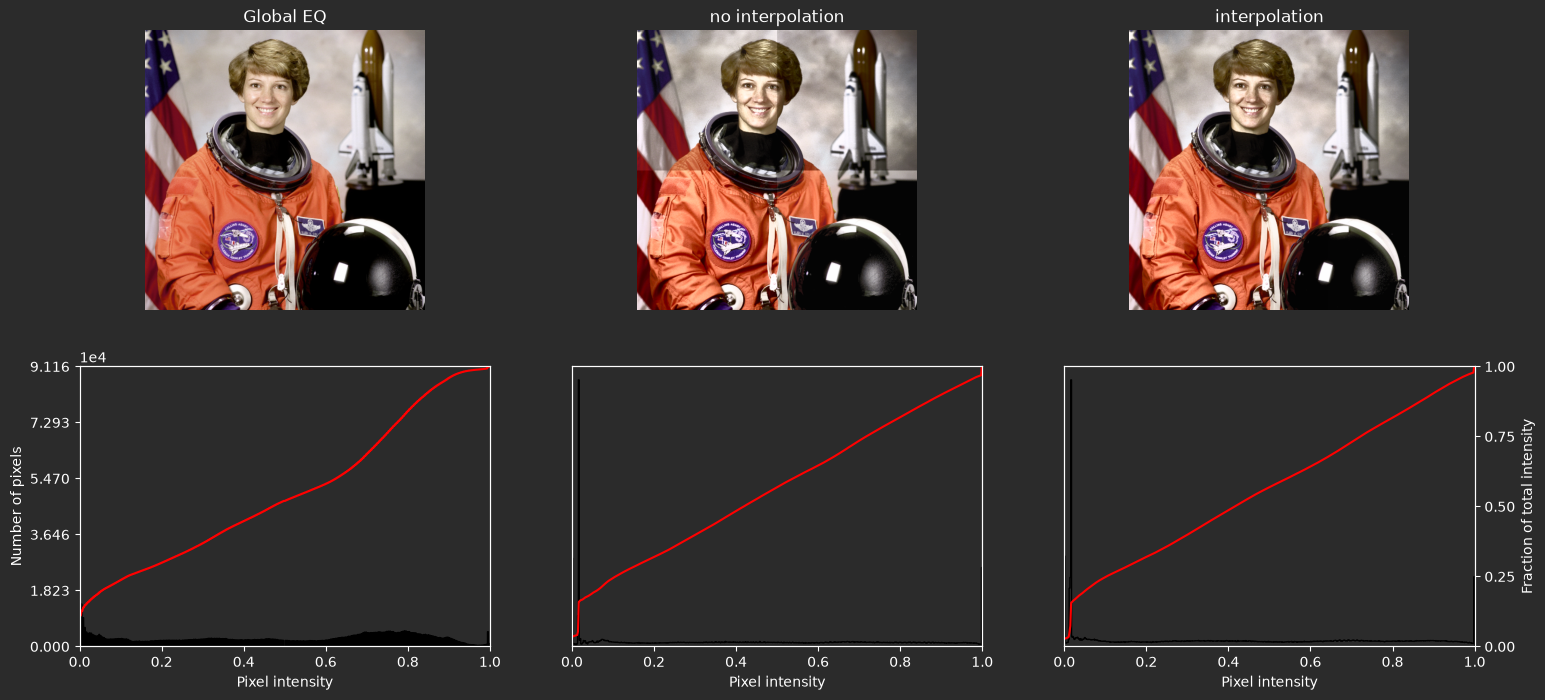

In [64]:
fig = plt.figure(figsize=(18, 8))
axes = np.zeros((2, 3), dtype=object)
axes[0, 0] = fig.add_subplot(2, 3, 1)
for i in range(1, 3):
    axes[0, i] = fig.add_subplot(2, 3, 1 + i, sharex=axes[0, 0], sharey=axes[0, 0])
for i in range(0, 3):
    axes[1, i] = fig.add_subplot(2, 3, 4 + i)

ax_img, ax_hist, ax_cdf = plot_img_and_hist(img, axes[:, 0])
ax_img.set_title('Global EQ')

y_min, y_max = ax_hist.get_ylim()
ax_hist.set_ylabel('Number of pixels')
ax_hist.set_yticks(np.linspace(0, y_max, 6))

ax_img, ax_hist, ax_cdf = plot_img_and_hist(no_interp, axes[:, 1])
ax_img.set_title('no interpolation')

ax_img, ax_hist, ax_cdf = plot_img_and_hist(interp, axes[:, 2])
ax_img.set_title('interpolation')

ax_cdf.set_ylabel('Fraction of total intensity')
ax_cdf.set_yticks(np.linspace(0, 1, 5));